# Lab 07 — Vector Space Model with ML

In the previous labs documents were represented with sparse **tf-idf** vectors (reduced with LSA/SVD). In this lab we replace that representation with **dense, fixed-size vectors produced by a pretrained neural network**, and keep everything else in the vector space model the same: documents and queries live in one space, and relevance is **cosine similarity**.

### Searching in the curious facts database

The [facts dataset](https://raw.githubusercontent.com/hsu-ai-course/hsu.ai/master/code/datasets/nlp/facts.txt) contains 159 short curious facts. We want to retrieve the facts **relevant to a query** (whatever that means): for the query "good mood" we hope to learn that *Cherophobia is the fear of fun*, even though the two texts share no words.

**Pipeline**
<div style="width: 900px;">

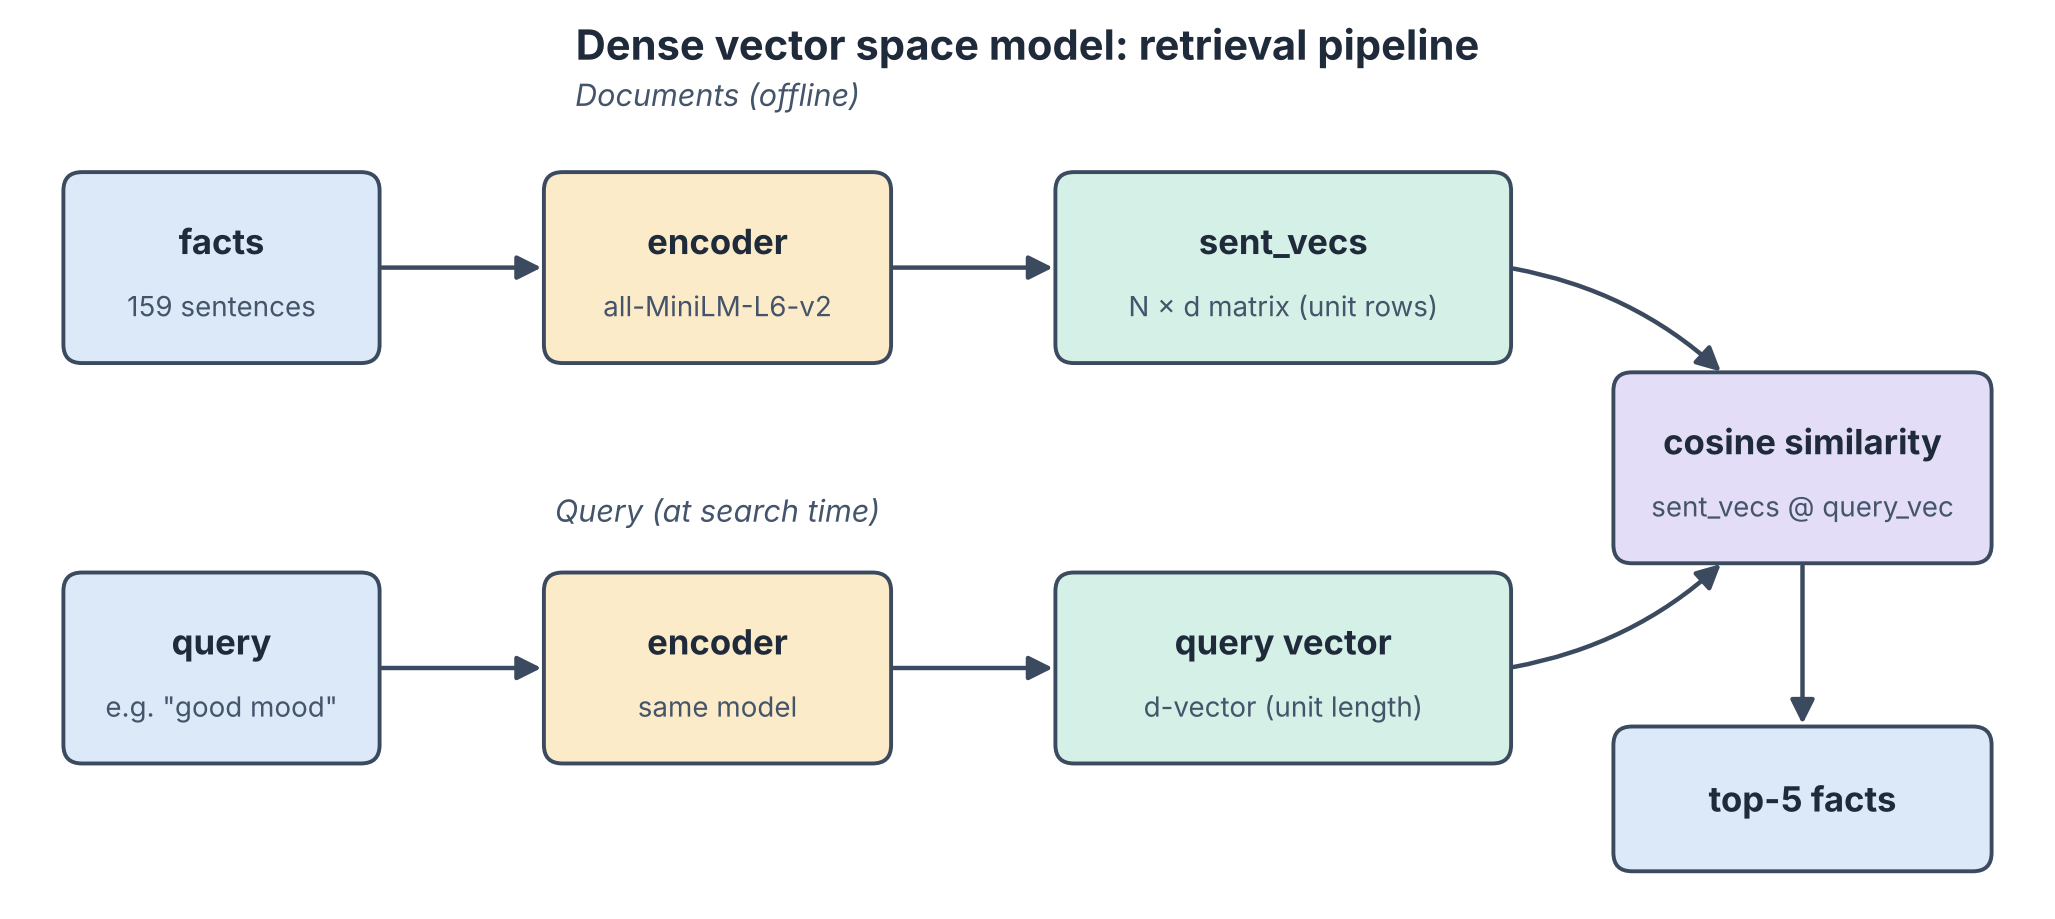

</div>

## 1.1. Use neural networks to embed sentences

Any encoder that maps text to a fixed-size vector works (doc2vec, Universal Sentence Encoder, BERT-style Transformers, ...). We use **Sentence-Transformers** with `all-MiniLM-L6-v2`:

- trained specifically so that **cosine similarity between sentence embeddings reflects semantic similarity**;
- small (~90 MB, 384 dimensions) and fast on CPU, so the whole lab runs in seconds;
- a single `pip install`, no spaCy or TensorFlow dependencies.

Other options you can try by changing `MODEL_NAME`: [SBERT pretrained models](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html), e.g. `multi-qa-MiniLM-L6-cos-v1` (tuned for question→passage search) or `all-mpnet-base-v2` (larger, usually better).

**Requirements:** Python ≥ 3.10, internet access on the first run (the model is downloaded and cached).

In [2]:
!uv add sentence-transformers

Resolved 221 packages in 3.41s                                       
Prepared 22 packages in 1m 14s                                               torch                 ------------------------------ 528.36 MiB/528.86 MiB      torch                 ------------------------------ 523.31 MiB/528.86 MiB      torch                 ------------------------------ 234.86 MiB/528.86 MiB      torch                 ------------------------------ 204.53 MiB/528.86 MiB      torch                 ------------------------------ 40.64 MiB/528.86 MiB       torch                 ------------------------------ 12.56 MiB/528.86 MiB       torch                 ------------------------------ 6.93 MiB/528.86 MiB        torch                 ------------------------------ 4.03 MiB/528.86 MiB        torch                 ------------------------------ 3.24 MiB/528.86 MiB        Atorch                 ------------------------------ 792.56 KiB/528.86 MiB      torch                 ------------------------------

In [ ]:
!uv tree -d 1

Resolved 221 packages in 4ms
ir v0.1.0
├── altair v6.2.2
├── beautifulsoup4 v4.15.0
├── bs4 v0.0.2
├── feedparser v6.0.14
├── ipykernel v7.3.0
├── matplotlib v3.10.9
├── nltk v3.10.3
├── pandas v2.3.3
├── requests v2.34.2
├── scikit-learn v1.7.2
├── selenium v4.48.0
├── sentence-transformers v6.2.0
└── statsmodels v0.15.0


In [ ]:
# %pip install -q sentence-transformers scikit-learn numpy scipy

In [1]:
import random
import re
import time
import urllib.request
from pathlib import Path

import numpy as np
from sentence_transformers import SentenceTransformer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

t0 = time.time()
model = SentenceTransformer(MODEL_NAME)          # device (CPU / CUDA / MPS) is chosen automatically
dim = model.get_sentence_embedding_dimension()

print(f"Model      : {MODEL_NAME}")
print(f"Device     : {model.device}")
print(f"Dimensions : {dim}")
print(f"Max tokens : {model.max_seq_length}  (longer inputs are truncated)")
print(f"Loaded in  : {time.time() - t0:.1f}s")

/home/firasj/workspace/inno/ir/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2011.08it/s]


Model      : sentence-transformers/all-MiniLM-L6-v2
Device     : cuda:0
Dimensions : 384
Max tokens : 256  (longer inputs are truncated)
Loaded in  : 27.5s


/tmp/ipykernel_5208/3906740960.py:18: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dim = model.get_sentence_embedding_dimension()


## 1.2. Write a function that prepares embedding

`embed(text)` returns a fixed-size vector. Two design decisions:

1. **Vectors are L2-normalised** (`normalize_embeddings=True`). For unit vectors, cosine similarity is just a dot product, so ranking all documents is a single matrix–vector product.
2. A batched helper `embed_many()` encodes many texts at once, which is much faster than calling `embed()` in a loop.

In [2]:
def embed_many(texts, batch_size: int = 64) -> np.ndarray:
    """Encode a list of texts into an (n, d) float32 matrix of unit-length vectors."""
    vectors = model.encode(
        list(texts),
        batch_size=batch_size,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False,
    )
    return vectors.astype(np.float32)


def embed(text: str) -> np.ndarray:
    """Return a fixed-size (d,) unit-length embedding of `text`."""
    if not isinstance(text, str):
        raise TypeError("embed() expects a string")
    return embed_many([text])[0]

In [1]:
assert len(embed("Some random text")) == len(embed("Folks, here's a story about Minnie the Moocher. She was a lowdown hoochie coocher. She was the roughest, toughest frail, but Minnie had a heart as big as a whale")), "Length should match"
print("Length test passed, vector size =", len(embed("Some random text")))

NameError: name 'embed' is not defined

In [8]:
from scipy.spatial.distance import cosine

assert abs(cosine(
            embed("some text for testing"),
            embed("some text for testing")
        )) < 1e-4, "Embedding should match"

assert abs(cosine(
            embed("Cats eat mice."),
            embed("Terminator is an autonomous cyborg, typically humanoid, originally conceived as a virtually indestructible soldier, infiltrator, and assassin.")
        )) > 0.2, "Embeddings should be far"

# Extra sanity checks: similar meaning -> small distance, different meaning -> large distance
d_similar = cosine(embed("A cat is chasing a mouse."), embed("Cats hunt mice."))
d_different = cosine(embed("A cat is chasing a mouse."), embed("The stock market fell sharply today."))
print(f"Similar sentences: cosine (distance = {d_similar:.3f}, similarity = {1-d_similar:.3f})")
print(f"Unrelated sentences: cosine (distance = {d_different:.3f}, similarity = {1-d_different:.3f})")
assert d_similar < d_different

Similar sentences: cosine (distance = 0.293, similarity = 0.707)
Unrelated sentences: cosine (distance = 0.917, similarity = 0.083)


## 1.3. Reading the data

Download the facts dataset and read it into a list of sentences. The file is cached locally (`facts.txt`), so it is downloaded only once.

We keep two parallel lists:
- `facts_clean` — the plain sentences, which are what we **embed** (a leading "67." number would only add noise to the vectors);
- `facts` — the same sentences with their 1-based number in front, which is what we **display**.

In [9]:
url = "https://raw.githubusercontent.com/hsu-ai-course/hsu.ai/master/code/datasets/nlp/facts.txt"
DATA_PATH = Path("facts.txt")


def load_facts(url: str, path: Path = DATA_PATH) -> list:
    """Download the dataset once (cached on disk) and return a list of non-empty lines."""
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return [line.strip() for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


NUMBER_PREFIX = re.compile(r"^\d+\.\s*")                       # "67. text" -> "text"

raw_lines = load_facts(url)
facts_clean = [NUMBER_PREFIX.sub("", line) for line in raw_lines]
facts = [f"{i}. {text}" for i, text in enumerate(facts_clean, start=1)]

In [ ]:
print(*facts[:5], sep='\n')
print(len(facts))

1. If you somehow found a way to extract all of the gold from the bubbling core of our lovely little planet, you would be able to cover all of the land in a layer of gold up to your knees.
2. McDonalds calls frequent buyers of their food "heavy users."
3. The average person spends 6 months of their lifetime waiting on a red light to turn green.
4. The largest recorded snowflake was in Keogh, MT during year 1887, and was 15 inches wide.
5. You burn more calories sleeping than you do watching television.
159


## 1.4. Transforming sentences to vectors

Transform the list of facts into a `numpy.array` of vectors, one row per document (`sent_vecs`), using the model we just loaded.

In [13]:
t0 = time.time()
sent_vecs = embed_many(facts_clean)
print(f"sent_vecs: shape={sent_vecs.shape}, dtype={sent_vecs.dtype}, encoded in {time.time() - t0:.1f}s")

sent_vecs: shape=(159, 384), dtype=float32, encoded in 0.4s


In [19]:
print(sent_vecs.shape[0] == len(facts), sent_vecs.shape[1] == dim)

# rows should be unit length
print(np.linalg.norm(sent_vecs, axis=1), np.allclose(np.linalg.norm(sent_vecs, axis=1), 1.0, atol=1e-4))

True True
[0.99999994 1.         1.         1.         1.         1.0000001
 1.         0.99999994 1.         1.         1.         1.
 1.         0.99999994 1.         1.         1.         1.
 1.         1.         1.         1.         0.99999994 1.
 1.         1.         1.         1.         1.         1.
 1.         1.         0.99999994 1.         1.         1.
 1.         1.         1.0000001  1.         1.         1.
 0.99999994 1.         0.99999994 1.         1.         1.
 0.99999994 0.99999994 1.         1.         1.         0.99999994
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         0.99999994 1.         1.
 1.         1.         1.         1.         1.         1.
 0.99999994 1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.      

## 1.5. Find closest

Find the 5 facts closest to the query using **cosine similarity**. Because all vectors are unit length, the cosine similarity of the query to every fact is one matrix–vector product, `sent_vecs @ query_vec`. We use `np.argpartition` to pick the top-k without fully sorting all documents, then sort only those k.

In [20]:
def search(query: str, k: int = 5):
    """Return the k most similar facts as a list of (index, cosine similarity), best first."""
    scores = sent_vecs @ embed(query)                          # cosine similarity to every fact
    k = min(k, len(scores) - 1)
    top = np.argpartition(-scores, k)[:k]                      # k best, unordered
    top = top[np.argsort(-scores[top])]                        # order them
    return [(int(i), float(scores[i])) for i in top]


def show(query: str, k: int = 5):
    print("Results for query:", query)
    for i, score in search(query, k):
        print(f"\t[{score:.3f}] {facts[i]}")


query = "good mood"
show(query)

Results for query: good mood
	[0.303] 61. Gorillas burp when they are happy
	[0.163] 28. A broken clock is right two times every day.
	[0.162] 48. Honey never spoils.
	[0.157] 88. You are 1% shorter in the evening than in the morning
	[0.151] 148. Dolphins sleep with one eye open!


In [29]:
# Sanity check: the fast dot-product ranking agrees with scipy's cosine distance
q = embed(query)
top_idx, top_score = search(query, 1)[0]
print(top_idx, top_score)
# abs((1 - cosine(q, sent_vecs[top_idx])) - top_score) < 1e-4, top_idx == int(np.argmin([cosine(q, v) for v in sent_vecs]))
(1 - cosine(q, sent_vecs[top_idx])), np.argmin([cosine(q, v) for v in sent_vecs])

60 0.30291110277175903


(np.float32(0.30291116), np.int64(60))

## 1.6. Recommend 5 facts to each of the queries for the following query bucket

```
good mood
gorilla
woman
earth
japan
people
math
```

Recommend 5 facts to each of the queries.

In [30]:
queries = ["good mood", "gorilla", "woman", "earth", "japan", "people", "math"]

for q in queries:
    show(q, k=5)
    print()

Results for query: good mood
	[0.303] 61. Gorillas burp when they are happy
	[0.163] 28. A broken clock is right two times every day.
	[0.162] 48. Honey never spoils.
	[0.157] 88. You are 1% shorter in the evening than in the morning
	[0.151] 148. Dolphins sleep with one eye open!

Results for query: gorilla
	[0.602] 61. Gorillas burp when they are happy
	[0.602] 141. Human birth control pills work on gorillas.
	[0.597] 59. The word "gorilla" is derived from a Greek word meaning, "A tribe of hairy women."
	[0.379] 113. Cows kill more people than sharks do.
	[0.363] 89. The elephant is the only mammal that can't jump!

Results for query: woman
	[0.346] 155. Women have twice as many pain receptors on their body than men. But a much higher pain tolerance.
	[0.267] 16. Men are 6 times more likely to be struck by lightning than women.
	[0.243] 66. A woman from California once tried to sue the makers of Cap'n Crunch, because the Crunch Berries contained "no berries of any kind."
	[0.229] 135

**Things to notice when you read the results**

- Queries such as `gorilla` or `japan` work even when the word is absent from a fact — the model matches *concepts* (animals, East Asia), which tf-idf cannot do.
- Single-word queries like `woman`, `people` or `math` are short and ambiguous, so results are noisier. Sentence encoders are trained on sentence-length inputs; richer queries ("facts about pregnancy") usually work better.
- A fact can be *topically related* without being *relevant*. Judging this properly requires human relevance assessments, which is what the bonus part does.

## 1.7. Write your own relevance assessments and compute DCG@5

To evaluate a ranking objectively we need **relevance judgments**. Below, a few facts per query are graded by hand:

| grade | meaning |
|---|---|
| 3 | directly answers / is clearly about the query |
| 2 | clearly related |
| 1 | marginally related |
| 0 | not relevant (also the default for every fact we did not judge) |

Judgments are stored as *text fragments of facts* rather than positions, so they stay valid whatever model produced the ranking. **Extend or correct them** after reading your own results — this is the "write your own assessments" part.

**Metrics** (ranks start at 1):

$$\mathrm{DCG@k}=\sum_{i=1}^{k}\frac{rel_i}{\log_2(i+1)}\qquad \mathrm{NDCG@k}=\frac{\mathrm{DCG@k}}{\mathrm{IDCG@k}}$$

where IDCG@k is the DCG of the ideal ordering of all judged facts, so NDCG lies in [0, 1] and is comparable across queries.

In [42]:
# query -> {fragment of a fact: grade}.  Facts not listed are treated as grade 0.
judgments = {
    "good mood": {"Cherophobia": 3, "Gorillas burp when they are happy": 2, "good luck in Japan": 1},
    "gorilla":   {"Gorillas burp when they are happy": 3},
    "woman":     {"pregnant woman has organ damage": 3, "Swedish woman lost her wedding ring": 3, "marry a dead person": 1},
    "earth":     {"Earth is the only planet that is not named after a god": 3, "1.6 million ants": 2,
                  "Saturn's density": 1, "rains diamonds": 1},
    "japan":     {"good luck in Japan": 3, "crooked teeth are considered cute": 3},
    "people":    {"33 million people held hands": 2, "Cows kill more people": 2,
                  "95% of people text": 2, "more lifeforms living on your skin than there are people": 2},
    "math":      {"111,111,111 X 111,111,111": 3, "simple mathematical calculations": 2},
}


def grade(fact_text: str, query: str) -> int:
    """Relevance grade of a fact for a query according to `judgments` (0 if unjudged)."""
    return max((g for frag, g in judgments.get(query, {}).items() if frag in fact_text), default=0)


def dcg(rels, k: int = 5) -> float:
    """DCG@k of a list of graded relevances listed in ranked order."""
    rels = np.asarray(rels, dtype=float)[:k]
    discounts = 1.0 / np.log2(np.arange(2, len(rels) + 2))     # 1/log2(i+1), i = 1..k
    return float(np.sum(rels * discounts))


def ndcg(rels, query: str, k: int = 5) -> float:
    """NDCG@k: DCG@k divided by the DCG of the best possible ranking of all judged facts."""
    ideal = sorted((grade(f, query) for f in facts_clean), reverse=True)
    idcg = dcg(ideal, k)
    return dcg(rels, k) / idcg if idcg > 0 else 0.0


# Sanity checks for the metric implementation
print(abs(dcg([3, 2, 3, 0, 1, 2], k=5)))
print(dcg([0, 0, 0, 0, 0]))
print(dcg([1] * 5))
print(judgments)
# Every judgment fragment must match at least one fact (catches typos)
for q, frags in judgments.items():
    for frag in frags:
        print([index for index, value in enumerate([frag in f for f in facts_clean]) if value])

6.148712314377457
0.0
2.9484591188793923
{'good mood': {'Cherophobia': 3, 'Gorillas burp when they are happy': 2, 'good luck in Japan': 1}, 'gorilla': {'Gorillas burp when they are happy': 3}, 'woman': {'pregnant woman has organ damage': 3, 'Swedish woman lost her wedding ring': 3, 'marry a dead person': 1}, 'earth': {'Earth is the only planet that is not named after a god': 3, '1.6 million ants': 2, "Saturn's density": 1, 'rains diamonds': 1}, 'japan': {'good luck in Japan': 3, 'crooked teeth are considered cute': 3}, 'people': {'33 million people held hands': 2, 'Cows kill more people': 2, '95% of people text': 2, 'more lifeforms living on your skin than there are people': 2}, 'math': {'111,111,111 X 111,111,111': 3, 'simple mathematical calculations': 2}}
[71]
[60]
[63]
[60]
[134]
[68]
[149]
[91]
[156]
[129]
[158]
[63]
[67]
[90]
[112]
[37]
[5]
[100]
[122]


In [43]:
def dense_ranker(query: str, k: int = 5):
    return [i for i, _ in search(query, k)]


def evaluate(ranker, k: int = 5, verbose: bool = True):
    """Mean DCG@k and NDCG@k of `ranker(query, k) -> list of fact indices` over the judged queries."""
    dcgs, ndcgs = [], []
    if verbose:
        print(f"{'query':<10} {'relevances@5':<18} {'DCG@5':>6} {'NDCG@5':>7}")
    for q in judgments:
        rels = [grade(facts_clean[i], q) for i in ranker(q, k)]
        dcgs.append(dcg(rels, k))
        ndcgs.append(ndcg(rels, q, k))
        if verbose:
            print(f"{q:<10} {str(rels):<18} {dcgs[-1]:>6.2f} {ndcgs[-1]:>7.2f}")
    return float(np.mean(dcgs)), float(np.mean(ndcgs))


# assessment[i] = graded relevances of the top-5 results of the i-th query
assessment = [[grade(facts_clean[i], q) for i in dense_ranker(q, 5)] for q in judgments]

print("Mean DCG@5 (same formula as the template):", sum([dcg(row) for row in assessment]) / len(assessment))
print()
mean_dcg, mean_ndcg = evaluate(dense_ranker)
print(f"\nMean DCG@5 = {mean_dcg:.3f}   Mean NDCG@5 = {mean_ndcg:.3f}")

Mean DCG@5 (same formula as the template): 2.697609236285314

query      relevances@5        DCG@5  NDCG@5
good mood  [2, 0, 0, 0, 0]      2.00    0.42
gorilla    [3, 0, 0, 0, 0]      3.00    1.00
woman      [0, 0, 0, 3, 3]      2.45    0.45
earth      [3, 0, 0, 1, 0]      3.43    0.66
japan      [3, 0, 3, 0, 0]      4.50    0.92
people     [0, 0, 0, 0, 0]      0.00    0.00
math       [2, 0, 3, 0, 0]      3.50    0.82

Mean DCG@5 = 2.698   Mean NDCG@5 = 0.611


### Is the neural encoder really better than tf-idf?

Compare against the classical **tf-idf vector space model** from the earlier labs, ranked with the same cosine measure and scored with the same judgments.

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english", sublinear_tf=True) # tf = 1 + ln(count) (for count > 0)
doc_matrix = tfidf.fit_transform(facts_clean)                  # rows are L2-normalised by default


def tfidf_ranker(query: str, k: int = 5):
    scores = (doc_matrix @ tfidf.transform([query]).T).toarray().ravel()
    return list(np.argsort(-scores, kind="stable")[:k])


results = {
    "tf-idf (sparse)": evaluate(tfidf_ranker, verbose=False),
    f"{MODEL_NAME.split('/')[-1]} (dense)": evaluate(dense_ranker, verbose=False),
}

print(f"{'model':<34} {'mean DCG@5':>10} {'mean NDCG@5':>12}")
for name, (d, n) in results.items():
    print(f"{name:<34} {d:>10.3f} {n:>12.3f}")

model                              mean DCG@5  mean NDCG@5
tf-idf (sparse)                         2.525        0.493
all-MiniLM-L6-v2 (dense)                2.698        0.611


In [45]:
# Where tf-idf fails: no shared words -> no match.  Dense vectors still find related facts.
for q in ["good mood", "gorilla"]:
    print(f"--- {q!r}")
    print("tf-idf :", [facts[i][:60] + "..." for i in tfidf_ranker(q, 3)])
    print("dense  :", [facts[i][:60] + "..." for i in dense_ranker(q, 3)])

--- 'good mood'
tf-idf : ['64. It is considered good luck in Japan when a sumo wrestler...', '1. If you somehow found a way to extract all of the gold fro...', '2. McDonalds calls frequent buyers of their food "heavy user...']
dense  : ['61. Gorillas burp when they are happy...', '28. A broken clock is right two times every day....', '48. Honey never spoils....']
--- 'gorilla'
tf-idf : ['59. The word "gorilla" is derived from a Greek word meaning,...', '1. If you somehow found a way to extract all of the gold fro...', '2. McDonalds calls frequent buyers of their food "heavy user...']
dense  : ['61. Gorillas burp when they are happy...', '141. Human birth control pills work on gorillas....', '59. The word "gorilla" is derived from a Greek word meaning,...']


In [51]:
# Compare several pretrained encoders on the same judgments (downloads each model).
RUN_MODEL_COMPARISON = True
CANDIDATE_MODELS = [
    "sentence-transformers/all-MiniLM-L6-v2",
    "sentence-transformers/multi-qa-MiniLM-L6-cos-v1",
    "sentence-transformers/all-mpnet-base-v2",
]

if RUN_MODEL_COMPARISON:
    print(f"{'model':<48} {'mean DCG@5':>10} {'mean NDCG@5':>12}")
    for name in CANDIDATE_MODELS:
        m = SentenceTransformer(name)
        vecs = m.encode(facts_clean, normalize_embeddings=True, show_progress_bar=False)
        
        def ranker(q, k=5, m=m, vecs=vecs):
            s = vecs @ m.encode(q, normalize_embeddings=True)
            return list(np.argsort(-s, kind="stable")[:k])

        d, n = evaluate(ranker, verbose=False)
        print(f"{name:<48} {d:>10.3f} {n:>12.3f}")

model                                            mean DCG@5  mean NDCG@5


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1677.05it/s]


sentence-transformers/all-MiniLM-L6-v2                2.698        0.611


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1342.11it/s]


sentence-transformers/multi-qa-MiniLM-L6-cos-v1       2.851        0.623


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2016.57it/s]


sentence-transformers/all-mpnet-base-v2               2.294        0.511
